[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shuishen112/neural-networks/blob/main/lectures/08_transformers.ipynb)

# Lecture 8 — Attention and Transformers

**Neural Networks · Master's course**

The Transformer (Vaswani et al., 2017) is the architecture behind essentially every
modern large language model, and increasingly behind vision, speech and protein models
too. Its core operation, **attention**, is surprisingly simple: a differentiable,
content-based lookup table. In this lecture we will

1. motivate attention from the **bottleneck** of recurrent encoder–decoders,
2. implement **scaled dot-product attention** from scratch, and understand the $\sqrt{d_k}$
   by watching the softmax saturate,
3. add **masks** for padding and for causality,
4. build **multi-head attention** and check it against PyTorch's implementation,
5. inject order with **positional encodings** (sinusoidal and learned),
6. assemble the **Transformer block** (pre-LN residual + LayerNorm + MLP) and discuss
   encoder vs. decoder,
7. train a tiny Transformer on **sequence reversal** and look at its attention maps,
8. train a tiny **GPT-style** character model and sample from it, and
9. discuss the $O(n^2)$ cost of attention and what large-scale pretraining adds.

Everything is written with plain tensor operations so that nothing is hidden; the
models are tiny and train on a CPU in seconds.

In [1]:
import math
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(2)
plt.rcParams["figure.figsize"] = (5, 4)
plt.rcParams["axes.grid"] = True
print("torch", torch.__version__)

torch 2.14.1+cpu


## 1. Motivation: the bottleneck of sequence-to-sequence RNNs

In Lecture 7 an RNN **encoder** read a source sentence $\mathbf{x}_{1:S}$ into hidden states
$\mathbf{h}_1, \dots, \mathbf{h}_S$, and a **decoder** generated the target from the last one,
$\mathbf{h}_S$, alone. Two problems:

* **Bottleneck.** A 40-word sentence must be squeezed into one fixed-size vector. Translation
  quality of such models dropped sharply with sentence length.
* **Path length.** Information about the first source word must survive $S$ encoder steps plus
  the decoder steps — exactly the long paths along which gradients vanish.

**Attention** (Bahdanau, Cho & Bengio, 2015) keeps *all* encoder states and lets the decoder,
at each output step $t$, compute a weighted average of them with weights that depend on what
it currently needs:

$$\mathbf{c}_t = \sum_{j=1}^{S} \alpha_{tj}\,\mathbf{h}_j, \qquad
\alpha_{tj} = \frac{\exp\big(e(\mathbf{s}_{t-1}, \mathbf{h}_j)\big)}{\sum_{j'}\exp\big(e(\mathbf{s}_{t-1}, \mathbf{h}_{j'})\big)},$$

where $\mathbf{s}_{t-1}$ is the decoder state and $e$ a learned **score** function. Every source
position is now one step away from every target position. The Transformer's radical step was to
notice that, once you have attention, you no longer need the recurrence at all
("Attention is all you need"): use attention **within** a sequence too (*self-attention*), and
process all positions in parallel.

## 2. Scaled dot-product attention

Think of attention as a **soft dictionary lookup**. We have $S$ *keys*
$\mathbf{k}_j\in\mathbb{R}^{d_k}$, each with a *value* $\mathbf{v}_j \in \mathbb{R}^{d_v}$, and a
*query* $\mathbf{q}\in\mathbb{R}^{d_k}$. A hard dictionary returns the value whose key matches
the query exactly; attention returns a **convex combination** of all values, weighted by
how well each key matches:

$$\operatorname{attn}(\mathbf{q}, K, V) = \sum_j \operatorname{softmax}_j\!\Big(\frac{\mathbf{q}^\top\mathbf{k}_j}{\sqrt{d_k}}\Big)\,\mathbf{v}_j .$$

Stacking $T$ queries as rows of $Q\in\mathbb{R}^{T\times d_k}$, keys in $K\in\mathbb{R}^{S\times d_k}$
and values in $V\in\mathbb{R}^{S\times d_v}$, all queries are handled by two matrix products:

$$\boxed{\operatorname{Attention}(Q,K,V) = \operatorname{softmax}\!\Big(\frac{QK^\top}{\sqrt{d_k}}\Big)\,V}
\qquad A = \operatorname{softmax}(\cdot) \in \mathbb{R}^{T\times S}, \text{ rows sum to 1}.$$

The softmax is taken over the **key** dimension (each query distributes one unit of attention
over the keys). In *self*-attention, $Q$, $K$ and $V$ are all linear projections of the same
sequence $X$: $Q = XW_Q$, $K = XW_K$, $V = XW_V$.

We will use the convention of `F.scaled_dot_product_attention` for masks: a **boolean mask
with `True` means "this query may attend to this key"**; disallowed scores are set to $-\infty$
before the softmax, so they get exactly zero weight.

In [2]:
def attention(q, k, v, mask=None):
    """Scaled dot-product attention.

    q: (..., T, d_k), k: (..., S, d_k), v: (..., S, d_v)
    mask: bool tensor broadcastable to (..., T, S); True = allowed.
    Returns the output (..., T, d_v) and the attention weights (..., T, S).
    """
    d_k = q.shape[-1]
    scores = q @ k.transpose(-2, -1) / math.sqrt(d_k)          # (..., T, S)
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    weights = scores.softmax(dim=-1)
    return weights @ v, weights

# A soft lookup: four keys (here simply basis vectors) with scalar values 10, 20, 30, 40.
keys = torch.eye(4) * 3.0
values = torch.tensor([[10.0], [20.0], [30.0], [40.0]])
for qv in ([3.0, 0.0, 0.0, 0.0], [0.0, 0.0, 3.0, 0.0], [0.0, 0.0, 1.5, 1.5], [0.0, 0.0, 0.0, 0.0]):
    out, w = attention(torch.tensor([qv]), keys, values)
    print(f"query {qv} -> weights {w[0].numpy().round(3)} -> output {out.item():.2f}")

query [3.0, 0.0, 0.0, 0.0] -> weights [0.968 0.011 0.011 0.011] -> output 10.65
query [0.0, 0.0, 3.0, 0.0] -> weights [0.011 0.011 0.968 0.011] -> output 29.78
query [0.0, 0.0, 1.5, 1.5] -> weights [0.048 0.048 0.452 0.452] -> output 33.09
query [0.0, 0.0, 0.0, 0.0] -> weights [0.25 0.25 0.25 0.25] -> output 25.00


A query aligned with key 3 retrieves (mostly) value 30; a query halfway between keys 3 and 4
returns a blend; the zero query, which matches nothing, returns the plain average. Because every
step is differentiable, the network can **learn** what to put in queries, keys and values.

Our implementation agrees with PyTorch's fused kernel:

In [3]:
B, h, T, S, d_k, d_v = 2, 3, 5, 7, 8, 4
q, k, v = torch.randn(B, h, T, d_k), torch.randn(B, h, S, d_k), torch.randn(B, h, S, d_v)
mask = torch.rand(B, 1, T, S) > 0.3
mask[..., 0] = True                       # make sure every query can see at least one key
out_me, w_me = attention(q, k, v, mask)
out_ref = F.scaled_dot_product_attention(q, k, v, attn_mask=mask)
print("output shape", tuple(out_me.shape), "| weights shape", tuple(w_me.shape))
print("matches F.scaled_dot_product_attention:", torch.allclose(out_me, out_ref, atol=1e-5))
print("rows of the attention matrix sum to 1:", torch.allclose(w_me.sum(-1), torch.ones(B, h, T)))

output shape (2, 3, 5, 4) | weights shape (2, 3, 5, 7)
matches F.scaled_dot_product_attention: True
rows of the attention matrix sum to 1: True


### Why divide by $\sqrt{d_k}$?

Suppose the components of $\mathbf{q}$ and $\mathbf{k}$ are independent with mean 0 and
variance 1 (roughly what we get at initialisation, and what LayerNorm encourages). Then

$$\mathbb{E}[\mathbf{q}^\top\mathbf{k}] = 0, \qquad
\operatorname{Var}[\mathbf{q}^\top\mathbf{k}] = \sum_{i=1}^{d_k}\operatorname{Var}[q_ik_i] = \sum_{i=1}^{d_k}\mathbb{E}[q_i^2]\,\mathbb{E}[k_i^2] = d_k .$$

The raw scores therefore have standard deviation $\sqrt{d_k}$. With $d_k = 512$ that is ~23:
differences between scores of tens of units, so the softmax is essentially a one-hot
**argmax**. A saturated softmax has a vanishing Jacobian,

$$\frac{\partial\,\operatorname{softmax}(\mathbf{z})}{\partial\mathbf{z}} = \operatorname{diag}(\mathbf{p}) - \mathbf{p}\mathbf{p}^\top \;\longrightarrow\; \mathbf{0}
\quad\text{as } \mathbf{p}\to \text{one-hot},$$

so almost no gradient flows to the queries and keys and learning stalls. Dividing by $\sqrt{d_k}$
restores unit variance regardless of the head dimension. Let us check this empirically.

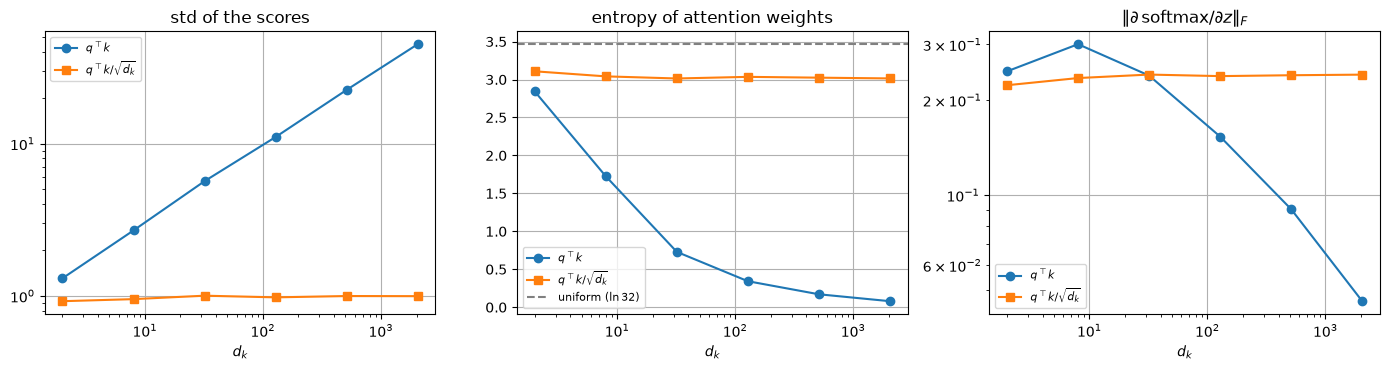

In [4]:
gen = torch.Generator().manual_seed(0)
dks = [2, 8, 32, 128, 512, 2048]
n_keys = 32
stats = {"raw": {"std": [], "ent": [], "jac": []}, "scaled": {"std": [], "ent": [], "jac": []}}
for dk in dks:
    qq = torch.randn(500, dk, generator=gen)
    kk = torch.randn(n_keys, dk, generator=gen)
    raw = qq @ kk.T                                            # (500, n_keys)
    for name, s in [("raw", raw), ("scaled", raw / math.sqrt(dk))]:
        p = s.softmax(-1)
        jac = torch.diag_embed(p) - p.unsqueeze(-1) * p.unsqueeze(-2)     # (500, n_keys, n_keys)
        stats[name]["std"].append(s.std().item())
        stats[name]["ent"].append(-(p * p.clamp_min(1e-30).log()).sum(-1).mean().item())
        stats[name]["jac"].append(max(jac.flatten(1).norm(dim=-1).mean().item(), 1e-12))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for name, style in [("raw", "o-"), ("scaled", "s-")]:
    label = "$q^\\top k$" if name == "raw" else "$q^\\top k / \\sqrt{d_k}$"
    axes[0].loglog(dks, stats[name]["std"], style, label=label)
    axes[1].semilogx(dks, stats[name]["ent"], style, label=label)
    axes[2].loglog(dks, stats[name]["jac"], style, label=label)
axes[1].axhline(math.log(n_keys), color="gray", ls="--", label="uniform ($\\ln 32$)")
axes[0].set_title("std of the scores"); axes[1].set_title("entropy of attention weights")
axes[2].set_title("$\\|\\partial\\,\\mathrm{softmax} / \\partial z\\|_F$")
for ax in axes:
    ax.set_xlabel("$d_k$"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Without scaling the attention becomes nearly one-hot (entropy → 0) and the softmax Jacobian
collapses by orders of magnitude as $d_k$ grows; with scaling all three statistics are
independent of $d_k$.

## 3. Masking

Two kinds of masks are used all the time.

**Padding mask.** Sequences in a batch are padded to a common length. Queries must not attend
to padding *keys*. With lengths $\ell_b$ the mask is $M_{b,j} = [\,j < \ell_b\,]$, shaped
`(B, 1, 1, S)` so that it broadcasts over heads and queries.

**Causal (look-ahead) mask.** In a language model, position $t$ predicts token $t+1$ and must
not see tokens after $t$; otherwise it could simply copy the answer. The mask is
lower-triangular: $M_{tj} = [\,j \le t\,]$. With it, the whole sequence can be trained **in
parallel** — one forward pass gives all $T$ next-token predictions — while every prediction
only depends on its past. This is the key training-efficiency advantage over RNNs.

> **Careful with conventions.** In `F.scaled_dot_product_attention` a boolean `True` means
> *allowed*. In `nn.MultiheadAttention` (`attn_mask`, `key_padding_mask`) a boolean `True`
> means *not allowed*. Always check the documentation — a flipped mask is a silent bug.

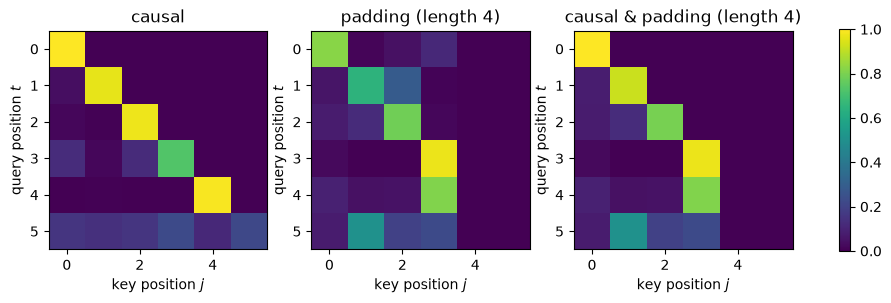

In [5]:
def causal_mask(T):
    return torch.tril(torch.ones(T, T, dtype=torch.bool))

def padding_mask(lengths, S):
    """(B,) lengths -> (B, 1, 1, S) bool mask, True for real tokens."""
    return (torch.arange(S)[None, :] < lengths[:, None])[:, None, None, :]

T = 6
lengths = torch.tensor([6, 4])
x_demo = torch.randn(2, 1, T, 8)                         # (B, heads, T, d)
_, w_causal = attention(x_demo, x_demo, x_demo, causal_mask(T))
_, w_pad = attention(x_demo, x_demo, x_demo, padding_mask(lengths, T))
_, w_both = attention(x_demo, x_demo, x_demo, causal_mask(T) & padding_mask(lengths, T))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, w, title in zip(axes, [w_causal[0, 0], w_pad[1, 0], w_both[1, 0]],
                        ["causal", "padding (length 4)", "causal & padding (length 4)"]):
    im = ax.imshow(w.numpy(), cmap="viridis", vmin=0, vmax=1)
    ax.set_title(title); ax.set_xlabel("key position $j$"); ax.set_ylabel("query position $t$")
    ax.grid(False)
plt.colorbar(im, ax=axes, shrink=0.8); plt.show()

Outputs at padded *query* positions are still computed (rows 4 and 5 on the right); they are
meaningless and are simply excluded from the loss. Note also that a query whose row is
**completely** masked would produce $\operatorname{softmax}(-\infty,\dots,-\infty) = $ `nan` —
this is why masks are designed so that every query sees at least one key.

## 4. Multi-head attention

A single attention head computes one weighted average per query, so it can only "look" in one
way at a time. **Multi-head attention** runs $h$ heads in parallel, each with its own
projections into a smaller space of dimension $d_k = d_{\text{model}}/h$, and concatenates the results:

$$
\begin{aligned}
\text{head}_i &= \operatorname{Attention}(XW_Q^{(i)},\, XW_K^{(i)},\, XW_V^{(i)}), \qquad W_Q^{(i)}, W_K^{(i)}, W_V^{(i)} \in\mathbb{R}^{d_{\text{model}}\times d_k}\\
\operatorname{MHA}(X) &= \big[\text{head}_1;\,\dots;\,\text{head}_h\big]\,W_O, \qquad W_O\in\mathbb{R}^{d_{\text{model}}\times d_{\text{model}}}.
\end{aligned}
$$

The cost is about the same as one head of full width. In code we never loop over heads: one
linear layer produces $Q$, $K$, $V$ for all heads, and we **reshape** `(B, T, d_model)` into
`(B, h, T, d_k)` so that the head dimension becomes a batch dimension of the matrix products.

In [6]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads, self.d_k = n_heads, d_model // n_heads
        self.in_proj = nn.Linear(d_model, 3 * d_model)     # W_Q, W_K, W_V for all heads at once
        self.out_proj = nn.Linear(d_model, d_model)        # W_O

    def forward(self, x, mask=None):
        B, T, E = x.shape
        q, k, v = self.in_proj(x).chunk(3, dim=-1)                       # 3 x (B, T, E)
        split = lambda t: t.reshape(B, T, self.n_heads, self.d_k).transpose(1, 2)   # (B, h, T, d_k)
        out, weights = attention(split(q), split(k), split(v), mask)     # (B, h, T, d_k)
        out = out.transpose(1, 2).reshape(B, T, E)                       # concatenate heads
        return self.out_proj(out), weights

`nn.MultiheadAttention` stores its parameters in exactly this layout (`in_proj_weight` of shape
$(3d, d)$ with the order $Q, K, V$, and `out_proj`), so we can copy them over and compare.
Remember its opposite mask convention: we pass `~causal_mask(T)`.

In [7]:
torch.manual_seed(0)
d_model, n_heads, T = 16, 4, 6
ref = nn.MultiheadAttention(d_model, n_heads, batch_first=True)
mine = MultiHeadAttention(d_model, n_heads)
with torch.no_grad():
    mine.in_proj.weight.copy_(ref.in_proj_weight)
    mine.in_proj.bias.copy_(ref.in_proj_bias)
    mine.out_proj.weight.copy_(ref.out_proj.weight)
    mine.out_proj.bias.copy_(ref.out_proj.bias)

x = torch.randn(3, T, d_model)
with torch.no_grad():
    y_mine, w_mine = mine(x, mask=causal_mask(T))
    y_ref, w_ref = ref(x, x, x, attn_mask=~causal_mask(T), need_weights=True, average_attn_weights=False)
print("outputs match:", torch.allclose(y_mine, y_ref, atol=1e-5))
print("per-head weights match:", torch.allclose(w_mine, w_ref, atol=1e-5), tuple(w_ref.shape))

outputs match: True
per-head weights match: True (3, 4, 6, 6)


## 5. Positional encodings

Self-attention treats its input as a **set**. If we permute the input positions with a
permutation matrix $P$, then $Q, K, V$ are permuted the same way and

$$\operatorname{softmax}\big(PQ(PK)^\top/\sqrt{d_k}\big)PV = P\,\operatorname{softmax}\big(QK^\top/\sqrt{d_k}\big)P^\top P V = P\,\operatorname{Attention}(Q,K,V),$$

using that the softmax acts row-wise and $P^\top P = I$. Self-attention is **permutation
equivariant**: "dog bites man" and "man bites dog" produce the same set of output vectors.
Let us verify:

In [8]:
perm = torch.randperm(T)
with torch.no_grad():
    y, _ = mine(x)
    y_perm, _ = mine(x[:, perm])
print("MHA(x[perm]) == MHA(x)[perm]:", torch.allclose(y_perm, y[:, perm], atol=1e-5))

MHA(x[perm]) == MHA(x)[perm]: True


To make order matter we add a **positional encoding** $\mathbf{p}_t\in\mathbb{R}^{d}$ to the token
embedding at position $t$: $\mathbf{x}_t \leftarrow \mathbf{e}(\text{token}_t) + \mathbf{p}_t$.

**Sinusoidal encoding** (Vaswani et al., 2017). With frequencies $\omega_i = 10000^{-2i/d}$,

$$p_{t,2i} = \sin(\omega_i t), \qquad p_{t,2i+1} = \cos(\omega_i t), \qquad i = 0,\dots,d/2-1.$$

Each pair of dimensions is a clock hand rotating at its own speed, from one turn every $2\pi$
positions down to one turn every $2\pi\cdot 10\,000$ positions — like the digits of a (continuous)
binary counter. Two properties make it attractive:

* **Relative positions are linear.** For every offset $k$ there is a fixed block-diagonal rotation
  $R_k$ (independent of $t$) with $\mathbf{p}_{t+k} = R_k\,\mathbf{p}_t$, by the angle-addition
  formulas. So "attend to the token 3 positions back" is easy to express with linear maps.
* **Dot products depend only on the offset:** $\mathbf{p}_t^\top\mathbf{p}_{t+k} = \sum_i \cos(\omega_i k)$.

**Learned encoding.** Simply learn a table $P\in\mathbb{R}^{T_{\max}\times d}$ (an `nn.Embedding`
over positions). This is what GPT-2 and BERT do. It is flexible but cannot extrapolate beyond
$T_{\max}$. Many current LLMs instead use *rotary* embeddings (RoPE), which rotate queries and keys
by position-dependent angles so that $\mathbf{q}_t^\top\mathbf{k}_j$ depends on $t-j$ directly.

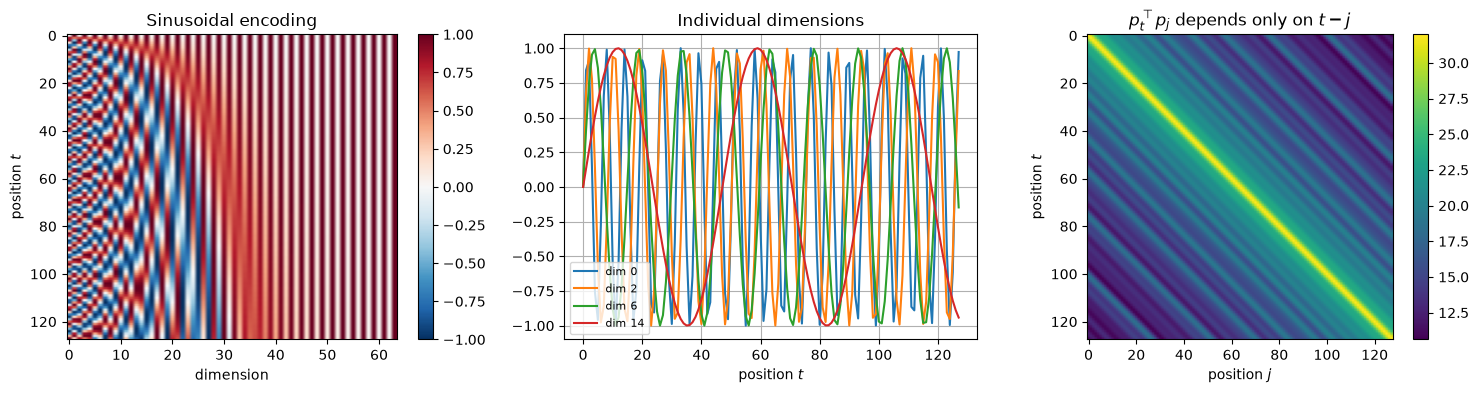

In [9]:
def sinusoidal_pe(n_pos, d):
    pos = torch.arange(n_pos, dtype=torch.float32)[:, None]               # (n_pos, 1)
    omega = torch.exp(-math.log(10000.0) * torch.arange(0, d, 2, dtype=torch.float32) / d)  # (d/2,)
    pe = torch.zeros(n_pos, d)
    pe[:, 0::2] = torch.sin(pos * omega)
    pe[:, 1::2] = torch.cos(pos * omega)
    return pe

pe = sinusoidal_pe(128, 64)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
im = axes[0].imshow(pe.numpy(), aspect="auto", cmap="RdBu_r")
axes[0].set_xlabel("dimension"); axes[0].set_ylabel("position $t$"); axes[0].set_title("Sinusoidal encoding")
axes[0].grid(False); plt.colorbar(im, ax=axes[0])
for i in [0, 2, 6, 14]:
    axes[1].plot(pe[:, i].numpy(), label=f"dim {i}")
axes[1].set_xlabel("position $t$"); axes[1].set_title("Individual dimensions"); axes[1].legend(fontsize=8)
im = axes[2].imshow((pe @ pe.T).numpy(), cmap="viridis")
axes[2].set_xlabel("position $j$"); axes[2].set_ylabel("position $t$")
axes[2].set_title("$p_t^\\top p_j$ depends only on $t-j$"); axes[2].grid(False); plt.colorbar(im, ax=axes[2])
plt.tight_layout(); plt.show()

A numerical check of the shift property: build $R_k$ from $2\times 2$ rotation blocks
$\begin{pmatrix}\cos\omega_i k & \sin\omega_i k\\ -\sin\omega_i k & \cos\omega_i k\end{pmatrix}$
and apply it to every position at once.

In [10]:
def shift_matrix(k, d):
    omega = torch.exp(-math.log(10000.0) * torch.arange(0, d, 2, dtype=torch.float32) / d)
    R = torch.zeros(d, d)
    c, s = torch.cos(omega * k), torch.sin(omega * k)
    idx = torch.arange(0, d, 2)
    R[idx, idx], R[idx, idx + 1] = c, s
    R[idx + 1, idx], R[idx + 1, idx + 1] = -s, c
    return R

k_shift = 5
R = shift_matrix(k_shift, 64)
print("p_{t+k} == R_k p_t for all t:", torch.allclose(pe[k_shift:], pe[:-k_shift] @ R.T, atol=1e-3))

p_{t+k} == R_k p_t for all t: True


## 6. The Transformer block

A Transformer is a stack of identical blocks. Each block has two sub-layers — **self-attention**,
which mixes information *across positions*, and a position-wise **MLP** (the "feed-forward
network"), which processes each position *independently* — each wrapped in a residual connection
and a LayerNorm. Modern models use the **pre-LN** arrangement:

$$
\begin{aligned}
X' &= X + \operatorname{MHA}\big(\operatorname{LN}(X)\big),\\
Y &= X' + \operatorname{MLP}\big(\operatorname{LN}(X')\big), \qquad \operatorname{MLP}(\mathbf{z}) = W_2\,\operatorname{GELU}(W_1\mathbf{z} + \mathbf{b}_1) + \mathbf{b}_2 .
\end{aligned}
$$

with the MLP hidden size typically $4d$. Recall from Lecture 5 that LayerNorm normalises each
token vector over its $d$ features (not over the batch), so it works for any batch size and
sequence length. Why this design?

* The **residual stream** $X \to X' \to Y$ is an identity path through the whole network, exactly as
  in ResNets (Lecture 6) and the LSTM cell state (Lecture 7): gradients reach early layers unchanged,
  and every sub-layer only *adds* a correction.
* In the original **post-LN** variant, $X' = \operatorname{LN}(X + \operatorname{MHA}(X))$, the
  normalisation sits *on* the residual path; deep post-LN models need careful learning-rate
  warm-up to train. Pre-LN keeps the residual path clean and is much more forgiving
  (Xiong et al., 2020). A final LayerNorm is applied after the last block.

**Encoder, decoder, encoder–decoder.**

| Variant | Attention mask | Typical use | Examples |
|---|---|---|---|
| Encoder-only | none (bidirectional) | classification, tagging, embeddings | BERT, ViT |
| Decoder-only | causal | language modelling, generation | GPT family, most LLMs |
| Encoder–decoder | encoder: none; decoder: causal + **cross-attention** to encoder outputs | translation, speech recognition | original Transformer, T5, Whisper |

In cross-attention the queries come from the decoder and the keys and values from the encoder —
precisely the Bahdanau attention of Section 1, without the RNN.

In [11]:
class TransformerBlock(nn.Module):
    """Pre-LN Transformer block."""
    def __init__(self, d_model, n_heads, d_ff, dropout=0.0):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, n_heads)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model))
        self.drop = nn.Dropout(dropout)
        self.attn_weights = None                         # stored for visualisation

    def forward(self, x, mask=None):
        a, w = self.attn(self.ln1(x), mask)
        self.attn_weights = w.detach()
        x = x + self.drop(a)
        x = x + self.drop(self.mlp(self.ln2(x)))
        return x


class TinyTransformer(nn.Module):
    """Token + learned positional embeddings -> blocks -> LayerNorm -> linear head."""
    def __init__(self, vocab, d_model=64, n_heads=4, n_layers=2, d_ff=256, max_len=64,
                 causal=False, dropout=0.0):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab, d_model)
        self.pos_emb = nn.Embedding(max_len, d_model)
        self.blocks = nn.ModuleList([TransformerBlock(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab)
        self.causal, self.max_len = causal, max_len

    def forward(self, idx):                                  # idx: (B, T) long
        B, T = idx.shape
        x = self.tok_emb(idx) + self.pos_emb(torch.arange(T, device=idx.device))   # (B, T, d)
        mask = causal_mask(T).to(idx.device) if self.causal else None
        for blk in self.blocks:
            x = blk(x, mask)
        return self.head(self.ln_f(x))                       # (B, T, vocab)

m = TinyTransformer(vocab=10)
print(f"{sum(p.numel() for p in m.parameters())} parameters;",
      "output shape", tuple(m(torch.randint(0, 10, (2, 8))).shape))

105482 parameters; output shape (2, 8, 10)


## 7. Demo: learning to reverse a sequence

Input: 8 random digits. Target: the same digits in reverse order, predicted at every position
(an aligned many-to-many task, so an **encoder-only** model suffices). Output position $t$ must
fetch the token at position $7-t$ — a purely *positional* lookup that attention can do in one
hop, whereas an RNN would have to store the whole sequence in its state first.

(5 s) token accuracy 1.000, whole-sequence accuracy 1.000


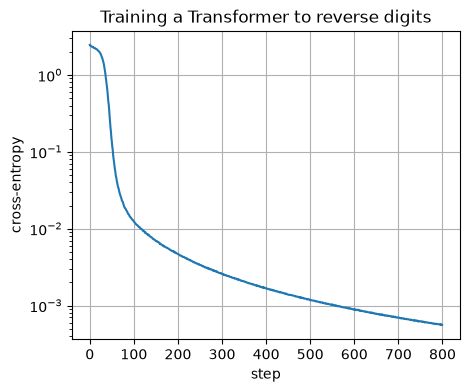

In [12]:
SEQ_LEN, N_DIGITS = 8, 10

def reverse_batch(B, gen):
    x = torch.randint(0, N_DIGITS, (B, SEQ_LEN), generator=gen)
    return x, x.flip(1)

torch.manual_seed(0)
gen = torch.Generator().manual_seed(0)
rev_model = TinyTransformer(N_DIGITS, d_model=64, n_heads=4, n_layers=2, d_ff=128, max_len=SEQ_LEN)
opt = torch.optim.AdamW(rev_model.parameters(), lr=1e-3, weight_decay=0.01)
rev_losses = []
t0 = time.time()
for step in range(800):
    x, y = reverse_batch(128, gen)
    loss = F.cross_entropy(rev_model(x).reshape(-1, N_DIGITS), y.reshape(-1))
    opt.zero_grad()
    loss.backward()
    opt.step()
    rev_losses.append(loss.item())

x_te, y_te = reverse_batch(2000, gen)
with torch.no_grad():
    pred = rev_model(x_te).argmax(-1)
tok_acc = (pred == y_te).float().mean().item()
seq_acc = (pred == y_te).all(dim=1).float().mean().item()
print(f"({time.time() - t0:.0f} s) token accuracy {tok_acc:.3f}, whole-sequence accuracy {seq_acc:.3f}")
plt.plot(rev_losses); plt.yscale("log"); plt.xlabel("step"); plt.ylabel("cross-entropy")
plt.title("Training a Transformer to reverse digits"); plt.show()

Now the attention maps for one test sequence: row $t$ shows how output position $t$ distributes
its attention over the input positions, for every head of every layer.

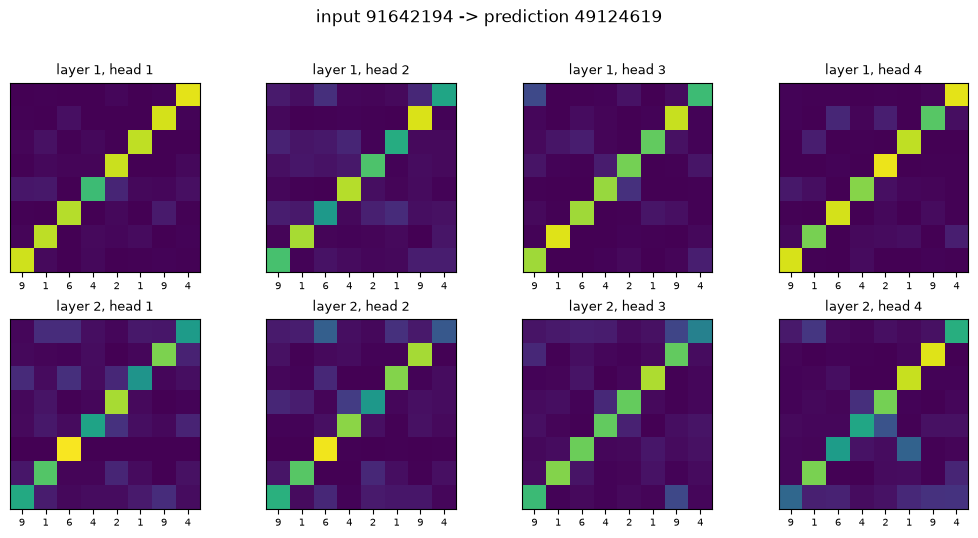

In [13]:
x_one = x_te[:1]
with torch.no_grad():
    rev_model(x_one)
n_layers, n_heads_ = len(rev_model.blocks), rev_model.blocks[0].attn.n_heads
fig, axes = plt.subplots(n_layers, n_heads_, figsize=(2.6 * n_heads_, 2.6 * n_layers))
labels = [str(d) for d in x_one[0].tolist()]
for l, blk in enumerate(rev_model.blocks):
    for hh in range(n_heads_):
        ax = axes[l, hh]
        ax.imshow(blk.attn_weights[0, hh].numpy(), cmap="viridis", vmin=0, vmax=1)
        ax.set_title(f"layer {l + 1}, head {hh + 1}", fontsize=9)
        ax.set_xticks(range(SEQ_LEN)); ax.set_xticklabels(labels, fontsize=7)
        ax.set_yticks([]); ax.grid(False)
plt.suptitle(f"input {''.join(labels)} -> prediction {''.join(map(str, pred[0].tolist()))}", y=1.02)
plt.tight_layout(); plt.show()

At least one head typically shows a clean **anti-diagonal**: output position $t$ attends to input
position $7-t$ — the model has discovered the algorithm, and attention maps make it directly
visible. (Which head, and how clean, depends on the random seed. Attention maps are a useful
window into a model, but in large models they must be interpreted with care: the residual stream
and the MLPs also carry information.)

## 8. Demo: a tiny GPT

A **decoder-only** Transformer with a causal mask is a language model: given tokens
$c_1,\dots,c_t$ it predicts $p(c_{t+1}\mid c_{\le t})$, at all positions in parallel. We train one on
another short original text, character by character, exactly as we trained the LSTM in
Lecture 7 — only the model changes.

2728 characters, vocabulary size 41
109481 parameters
step    0  train 3.930  val 3.914


step  100  train 2.326  val 2.434


step  200  train 2.067  val 2.384


step  300  train 1.710  val 2.275


step  400  train 1.341  val 2.295


...

step  600  train 0.783  val 2.758


step  700  train 0.591  val 2.936


step  800  train 0.609  val 3.028


step  900  train 0.512  val 2.960


step  999  train 0.538  val 3.115
(18 s)


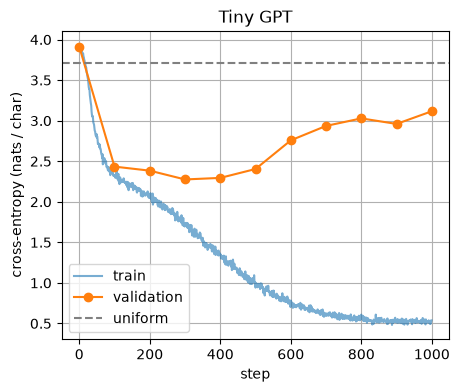

In [14]:
text = """In the small harbour town the year is measured by the light. In winter the sun rises late and sets early, and the street lamps are lit before the children walk home from school. People gather in kitchens, drink coffee from heavy cups and talk about the boats that are pulled up on land, waiting under grey covers for spring. The sea is dark and quiet, and on cold mornings a thin skin of ice grows along the edge of the bay.
In spring the light returns quickly, almost too quickly. Every week the evenings are longer, and the town seems to wake up all at once. The covers come off the boats, the hulls are scraped and painted, and the smell of tar and fresh wood drifts over the harbour. Old fishermen stand with their hands in their pockets and give advice that nobody has asked for, and the young ones listen politely and then do what they had planned to do anyway.
Summer is short and bright. The sun hardly sets, and at midnight the sky over the islands is still pale blue. Families from the city arrive with bicycles and baskets, the small cafe by the pier sells cinnamon buns until it runs out, and the children jump from the rocks into water that is colder than they expected. In the long evenings people sit outside, talk until late and forget to look at the clock, because the light makes it feel as if the day will never end.
Then autumn comes with wind and rain. The visitors leave, the cafe closes on weekdays, and the boats go back on land one by one. The forest behind the town turns yellow and red, and people walk there with baskets to look for mushrooms, each with a secret place that they will not reveal, not even to their closest friends. Storms arrive from the west, the windows rattle, and in the morning the beach is covered with seaweed and pieces of wood that the sea has carried from far away.
And so the year turns, and the town turns with it. Nothing much happens, and yet everything changes a little. A new family moves into the yellow house by the church, an old boat is finally sold, a tree falls in the storm and is cut into firewood for the next winter. The people who live there say that they could never live anywhere else, and when they are asked why, they talk about the light, the sea and the long summer evenings, and then they fall silent, as if the rest were too obvious to explain.
Visitors sometimes ask what people do there in the dark months, and the answer is always the same: they mend nets, they read, they visit each other, they bake bread and they wait. Waiting is not empty in the harbour town. It is a kind of work, like the slow work of the tide, which moves the sand a little every day until one morning the beach has a new shape and nobody can say exactly when it changed.
"""
chars = sorted(set(text))
V = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
data = torch.tensor([stoi[c] for c in text], dtype=torch.long)
n_train = int(0.9 * len(data))
train_data, val_data = data[:n_train], data[n_train:]
print(f"{len(text)} characters, vocabulary size {V}")

CTX = 64
def get_batch(split, B, gen):
    src = train_data if split == "train" else val_data
    ix = torch.randint(0, len(src) - CTX - 1, (B,), generator=gen).tolist()
    x = torch.stack([src[i:i + CTX] for i in ix])
    y = torch.stack([src[i + 1:i + CTX + 1] for i in ix])
    return x, y

torch.manual_seed(0)
gen = torch.Generator().manual_seed(0)
gpt = TinyTransformer(V, d_model=64, n_heads=4, n_layers=2, d_ff=256, max_len=CTX, causal=True, dropout=0.1)
print(f"{sum(p.numel() for p in gpt.parameters())} parameters")
opt = torch.optim.AdamW(gpt.parameters(), lr=2e-3, weight_decay=0.01)
steps = 1000
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=steps, pct_start=0.1)
train_losses, val_losses = [], []
t0 = time.time()
for step in range(steps):
    gpt.train()
    x, y = get_batch("train", 32, gen)
    loss = F.cross_entropy(gpt(x).reshape(-1, V), y.reshape(-1))
    opt.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(gpt.parameters(), 1.0)
    opt.step()
    sched.step()
    train_losses.append(loss.item())
    if step % 100 == 0 or step == steps - 1:
        gpt.eval()
        with torch.no_grad():
            xv, yv = get_batch("val", 64, gen)
            val_losses.append((step, F.cross_entropy(gpt(xv).reshape(-1, V), yv.reshape(-1)).item()))
        print(f"step {step:4d}  train {loss.item():.3f}  val {val_losses[-1][1]:.3f}")
print(f"({time.time() - t0:.0f} s)")

plt.plot(train_losses, alpha=0.6, label="train")
plt.plot(*zip(*val_losses), "o-", label="validation")
plt.axhline(math.log(V), color="gray", ls="--", label="uniform")
plt.xlabel("step"); plt.ylabel("cross-entropy (nats / char)"); plt.legend(); plt.title("Tiny GPT"); plt.show()

**Generation.** We feed the prompt, sample the next character with a temperature (Lecture 7),
append it, and repeat. The model has a fixed maximum context of $T_{\max}=64$ positions, so we
**crop** the input to the last 64 characters. Note that we recompute the whole context at every
step; production systems cache the keys and values of past positions (the **KV cache**) so that
each new token only costs one query against the stored keys.

In [15]:
@torch.no_grad()
def generate(model, prompt, n_new, temperature=1.0, seed=0):
    model.eval()
    gen = torch.Generator().manual_seed(seed)
    idx = torch.tensor([[stoi[c] for c in prompt]], dtype=torch.long)       # (1, len(prompt))
    for _ in range(n_new):
        logits = model(idx[:, -model.max_len:])[:, -1]                       # (1, V)
        probs = F.softmax(logits / temperature, dim=-1)
        nxt = torch.multinomial(probs, num_samples=1, generator=gen)         # (1, 1)
        idx = torch.cat([idx, nxt], dim=1)
    return "".join(itos[i] for i in idx[0].tolist())

for tau in [0.5, 0.8, 1.2]:
    print(f"--- temperature {tau} ---")
    print(generate(gpt, "In the ", 300, temperature=tau))
    print()

--- temperature 0.5 ---
In the light makes if the crocks into with indo baskets, thats the lock, bechiy closest frieht. In the sear and the long the long sumer, and the and the smand wind pold pover the with bout. Olight.
Sthe sulsir arris and quiet, and on cold from the hashe bay.
In the year turns, and the turn turns, and qunt,

--- temperature 0.8 ---


In the light makes if the not weekdays, they seecre cafres malk the cappe behinte long secehingers pear y onge lis beally and there sk one land, and the land the listen politely ared then do wing ther yes and they talk about the light chapple seamid with and the sell on lone. The lisetors a lythe long cove

--- temperature 1.2 ---
In the light makes if cup piece clos cahinnaps, and can lit the lomeoppeopre talk walk there indown ther in the reeboaths are longetowns ek ongs forish ingeto ark muck ch iclis coveret pped blier that thands, do hat in morning cows and rets the podery cous siver and qunt, then chin owsito, and on the bas t



Finally, check that the causal mask really works: changing a *future* character must not change
the predictions at earlier positions.

In [16]:
x, _ = get_batch("val", 1, gen)
x2 = x.clone()
x2[0, 40] = (x2[0, 40] + 1) % V
gpt.eval()
with torch.no_grad():
    diff = (gpt(x) - gpt(x2)).abs().amax(dim=-1)[0]                 # (CTX,)
print("max change of logits at positions < 40:", diff[:40].max().item())
print("max change of logits at positions >= 40:", diff[40:].max().item())

max change of logits at positions < 40: 0.0
max change of logits at positions >= 40: 10.573328971862793


## 9. Cost, efficient attention, and pretraining

**Complexity.** For a sequence of length $n$ and width $d$, self-attention needs
$O(n^2 d)$ time and materialises an $n\times n$ attention matrix per head: $O(n^2)$ memory. The
MLP costs $O(n d^2)$. For short sequences the MLP dominates; for long ones the quadratic term
does. Compare with an RNN: $O(n d^2)$ time, but $n$ **sequential** steps, whereas all of
attention's $n^2$ interactions can be computed in parallel. Let us time our naive implementation.

n =   128:     0.1 ms, attention matrix    0.2 MiB
n =   256:     0.3 ms, attention matrix    1.0 MiB
n =   512:     1.3 ms, attention matrix    4.0 MiB
n =  1024:     7.6 ms, attention matrix   16.0 MiB


n =  2048:    27.3 ms, attention matrix   64.0 MiB


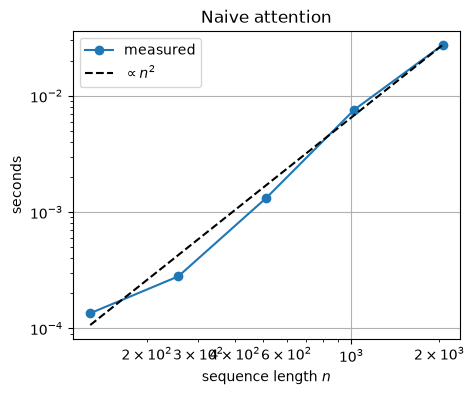

In [17]:
ns = [128, 256, 512, 1024, 2048]
times = []
for n in ns:
    qn = torch.randn(1, 4, n, 32)
    attention(qn, qn, qn)                                   # warm-up
    t0 = time.perf_counter()
    for _ in range(3):
        attention(qn, qn, qn)
    times.append((time.perf_counter() - t0) / 3)
    print(f"n = {n:5d}: {1000 * times[-1]:7.1f} ms, attention matrix {4 * n * n * 4 / 2**20:6.1f} MiB")
plt.loglog(ns, times, "o-", label="measured")
plt.loglog(ns, [times[-1] * (n / ns[-1]) ** 2 for n in ns], "k--", label="$\\propto n^2$")
plt.xlabel("sequence length $n$"); plt.ylabel("seconds"); plt.legend(); plt.title("Naive attention"); plt.show()

A lot of research targets this quadratic cost:

* **Memory-efficient exact attention.** *FlashAttention* (Dao et al., 2022) computes exactly the
  same result in tiles, using an online softmax, without ever storing the $n\times n$ matrix:
  $O(n)$ memory and much less memory traffic. `F.scaled_dot_product_attention` dispatches to such
  kernels when available — use it in practice.
* **Sparse / local attention** (sliding windows, e.g. Longformer, Mistral) restricts which keys each
  query sees.
* **Linear attention / kernel methods** (e.g. Performer) and **state-space models** (S4, Mamba)
  replace softmax attention by operators with $O(n)$ cost — interestingly, these are recurrent
  networks again in disguise.

**Pretraining and large language models.** The tiny GPT above is, architecturally, the same model
as GPT-2/3 and its successors: a decoder-only stack trained to predict the next token. What
changes is scale (billions of parameters, trillions of tokens of text), tokenisation (sub-word
units such as BPE instead of characters), and engineering. Models pretrained this way can then be
**fine-tuned** (or instruction-tuned and aligned with human feedback) for downstream tasks, or used
directly by prompting. Encoder-only models such as BERT are pretrained instead with **masked
language modelling** (predict randomly hidden tokens from both sides) and are used for
classification and retrieval. Empirically, loss improves as a smooth power law in parameters,
data and compute (**scaling laws**; Kaplan et al., 2020; Hoffmann et al., 2022) — one reason why
this simple architecture has been scaled so far.

## Summary

| Concept | Key equation / fact |
|---|---|
| Attention | $\operatorname{softmax}(QK^\top/\sqrt{d_k})\,V$: a soft, differentiable lookup |
| $\sqrt{d_k}$ scaling | $\operatorname{Var}[\mathbf{q}^\top\mathbf{k}] = d_k$; scaling avoids a saturated softmax |
| Masks | padding: hide padded keys; causal: $j \le t$ only. Mind the `True` convention! |
| Multi-head | $h$ heads of size $d/h$ in parallel, concatenated, then $W_O$ |
| Positional encoding | self-attention is permutation equivariant; add $\mathbf{p}_t$ (sinusoidal, learned, RoPE) |
| Pre-LN block | $X' = X + \operatorname{MHA}(\operatorname{LN}X)$, $Y = X' + \operatorname{MLP}(\operatorname{LN}X')$ |
| Variants | encoder (bidirectional), decoder (causal), encoder–decoder (cross-attention) |
| Cost | $O(n^2d)$ time, $O(n^2)$ memory (naive); FlashAttention, sparse, linear attention |

**Further reading.**
Vaswani et al. (2017), *Attention is all you need*;
Bahdanau, Cho & Bengio (2015), *Neural machine translation by jointly learning to align and translate*;
Xiong et al. (2020), *On layer normalization in the Transformer architecture*;
Radford et al. (2019), *Language models are unsupervised multitask learners* (GPT-2);
Devlin et al. (2019), *BERT*;
Dao et al. (2022), *FlashAttention*;
Phuong & Hutter (2022), *Formal algorithms for Transformers*;
Prince, *Understanding Deep Learning* (2023), ch. 12;
Karpathy, *nanoGPT* and the "Let's build GPT" lecture.